# Prediction Intervals and Coverage
**Author and maintainer: Sheima Alameeri, PhD**

A standalone educational experiment using synthetic data. Established statistical methods, not a new algorithm. No dissertation code or unpublished research is used.

## What does an interval describe?
A confidence interval here targets the conditional mean response at a fixed x. A prediction interval targets one independent future response and includes irreducible observation noise. Neither is a simultaneous band. Under a correctly specified linear mean, independent Gaussian errors of constant variance, and a full-rank design, the usual Student-t intervals have their nominal repeated-sampling coverage at fixed x.

For a prediction location $x_0$, define the column vector $\mathbf{z}_0=(1,x_0)^\top$. The design matrix $X$ has rows $(1,x_i)$, and $\widehat{y}_0=\mathbf{z}_0^\top\widehat{\boldsymbol{\beta}}$.

**Leverage and estimated residual variance**

```math
h_0=\mathbf{z}_0^\top(X^\top X)^{-1}\mathbf{z}_0,
\qquad
s^2=\frac{\sum_{i=1}^{n}(y_i-\widehat{y}_i)^2}{n-2}.
```

Here $n$ is the training sample size; $n-2$ is the residual degrees of freedom for an intercept and slope.

**95% confidence interval for the mean response at $x_0$**

```math
\widehat{y}_0 \;\pm\; t_{0.975,\,n-2}\,s\sqrt{h_0}.
```

**95% prediction interval for one future response at $x_0$**

```math
\widehat{y}_0 \;\pm\; t_{0.975,\,n-2}\,s\sqrt{1+h_0}.
```

The extra $1$ includes future observation noise. The quantity $t_{0.975,\,n-2}$ is the 97.5th percentile of Student's $t$ distribution with $n-2$ degrees of freedom.

## Experiment
We fit a straight line in all three scenarios: correct linear mean and constant noise; curved mean with constant noise; linear mean with changing noise. Each uses 4,000 independent training datasets. At each of three fixed x values, each replication generates one fresh future response. Coverage is the fraction captured; width is averaged over replications. No test responses tune the model.

For $B$ independent simulation replications, observed coverage at $x_0$ is

```math
\widehat{c}(x_0)=\frac{1}{B}\sum_{b=1}^{B}
\mathbf{1}\!\left\{L_b(x_0)\leq Y_b^{\mathrm{new}}(x_0)\leq U_b(x_0)\right\}.
```

Here $[L_b(x_0),U_b(x_0)]$ is the prediction interval in replication $b$, and the indicator equals one when it captures the future response. Mean interval width is

```math
\overline{w}(x_0)=\frac{1}{B}\sum_{b=1}^{B}\left[U_b(x_0)-L_b(x_0)\right].
```

The estimated Monte Carlo standard error is

```math
\widehat{\mathrm{MCSE}}\!\left[\widehat{c}(x_0)\right]
=\sqrt{\frac{\widehat{c}(x_0)\left[1-\widehat{c}(x_0)\right]}{B}}.
```

The plotted error bars are $\widehat{c}(x_0)\pm1.96\,\widehat{\mathrm{MCSE}}$.

These error bars quantify simulation error approximately; they are not prediction intervals. At observed coverage 0 or 1, plug-in MCSE is zero but this does not prove zero simulation uncertainty; use a binomial boundary interval for inference there. Outcomes at different x share training data and are correlated, so we do not pool them as independent trials. Misspecification can distort local coverage even if average coverage looks satisfactory.


In [1]:
# Educational tutorial | Sheima Alameeri, PhD
import numpy as np
from scipy.stats import t
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from pathlib import Path
import csv
rng=np.random.default_rng(20261028)
Path('assets').mkdir(exist_ok=True)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':11})
def fit_interval(x,y,z):
    X=np.column_stack([np.ones(len(x)),x]); Z=np.column_stack([np.ones(len(z)),z])
    beta=np.linalg.lstsq(X,y,rcond=None)[0]
    s2=np.sum((y-X@beta)**2)/(len(x)-2)
    h=np.einsum('ij,jk,ik->i',Z,np.linalg.inv(X.T@X),Z)
    q=t.ppf(.975,len(x)-2)
    return Z@beta,q*np.sqrt(s2*h),q*np.sqrt(s2*(1+h))
def save(fig,name):
    fig.text(.5,.015,'Sheima Alameeri, PhD | Prediction Intervals and Coverage',ha='center',fontsize=9,color='#24476b')
    fig.tight_layout(rect=[0,.05,1,1]);fig.savefig('assets/'+name+'.png',dpi=150);plt.close(fig)
x=np.linspace(-1,1,60);z=np.linspace(-1,1,200)
y=1+2*x+rng.normal(0,.5,len(x))
m,ci,pi=fit_interval(x,y,z)
assert np.all(pi>ci)
fig,ax=plt.subplots(figsize=(9,4.5));ax.fill_between(z,m-pi,m+pi,color='#b9d8ef',label='95% prediction interval');ax.fill_between(z,m-ci,m+ci,color='#337fb4',alpha=.6,label='95% confidence interval for mean');ax.plot(z,m,color='#123b64');ax.scatter(x,y,s=15,color='#245a84');ax.set(xlabel='x',ylabel='Response',title='Mean uncertainty versus a future observation');ax.legend();save(fig,'intervals')
# One independent training sample and one future observation per replication.
# This makes Bernoulli MCSE appropriate at each fixed x.
B=4000; points=np.array([-.9,0,.9]); rows=[]
for scenario in ['Correct linear / constant noise','Curved mean / constant noise','Linear mean / changing noise']:
    hits=[];widths=[]
    for b in range(B):
        xx=rng.uniform(-1,1,60)
        mean=lambda v: 1+2*v+(2*v*v if scenario.startswith('Curved') else 0)
        noise=lambda v: .2+.9*(v+1)/2 if scenario.endswith('changing noise') else np.full_like(v,.5)
        yy=mean(xx)+rng.normal(size=len(xx))*noise(xx)
        mm,_,pp=fit_interval(xx,yy,points)
        future=mean(points)+rng.normal(size=3)*noise(points)
        hits.append(np.abs(future-mm)<=pp);widths.append(2*pp)
    h=np.asarray(hits).mean(axis=0);w=np.asarray(widths).mean(axis=0)
    for j,v in enumerate(points):
        se=np.sqrt(h[j]*(1-h[j])/B)
        rows.append([scenario,v,h[j],se,w[j]])
with open('assets/coverage.csv','w') as f:
    writer=csv.writer(f);writer.writerow(['scenario','x','coverage','MCSE','mean_width']);writer.writerows(rows)
fig,axs=plt.subplots(1,2,figsize=(11,4.5))
for k,s in enumerate(sorted(set(r[0] for r in rows))):
    rr=[r for r in rows if r[0]==s]; xx=np.array([r[1] for r in rr])+(.025*(k-1))
    axs[0].errorbar(xx,[r[2] for r in rr],yerr=[1.96*r[3] for r in rr],fmt='o-',label=s,color=['#123b64','#3986b9','#70b4cc'][k])
    axs[1].plot(xx,[r[4] for r in rr],'o-',label=s,color=['#123b64','#3986b9','#70b4cc'][k])
axs[0].axhline(.95,color='gray',ls='--');axs[0].set(ylabel='Observed coverage',xlabel='Fixed prediction location x',title='Coverage: error bars = ±1.96 MCSE',ylim=(.65,1))
axs[1].set(ylabel='Mean prediction interval width',xlabel='Fixed prediction location x',title='Width alone cannot establish reliability')
axs[1].legend(fontsize=8);save(fig,'coverage-and-width')
correct=[r for r in rows if r[0].startswith('Correct')]
assert all(abs(r[2]-.95)<5*r[3] for r in correct)
assert all(np.isfinite(r[4]) and r[4]>0 for r in rows)
print('4000 independent replications per scenario; checks passed.')
for r in rows: print(f'{r[0]} | x={r[1]:.1f}: coverage={r[2]:.4f}, MCSE={r[3]:.4f}, width={r[4]:.3f}')


4000 independent replications per scenario; checks passed.
Correct linear / constant noise | x=-0.9: coverage=0.9467, MCSE=0.0036, width=2.050
Correct linear / constant noise | x=0.0: coverage=0.9540, MCSE=0.0033, width=2.009
Correct linear / constant noise | x=0.9: coverage=0.9460, MCSE=0.0036, width=2.050
Curved mean / constant noise | x=-0.9: coverage=0.8695, MCSE=0.0053, width=3.182
Curved mean / constant noise | x=0.0: coverage=0.9550, MCSE=0.0033, width=3.119
Curved mean / constant noise | x=0.9: coverage=0.8652, MCSE=0.0054, width=3.182
Linear mean / changing noise | x=-0.9: coverage=1.0000, MCSE=0.0000, width=2.861
Linear mean / changing noise | x=0.0: coverage=0.9607, MCSE=0.0031, width=2.804
Linear mean / changing noise | x=0.9: coverage=0.8037, MCSE=0.0063, width=2.860


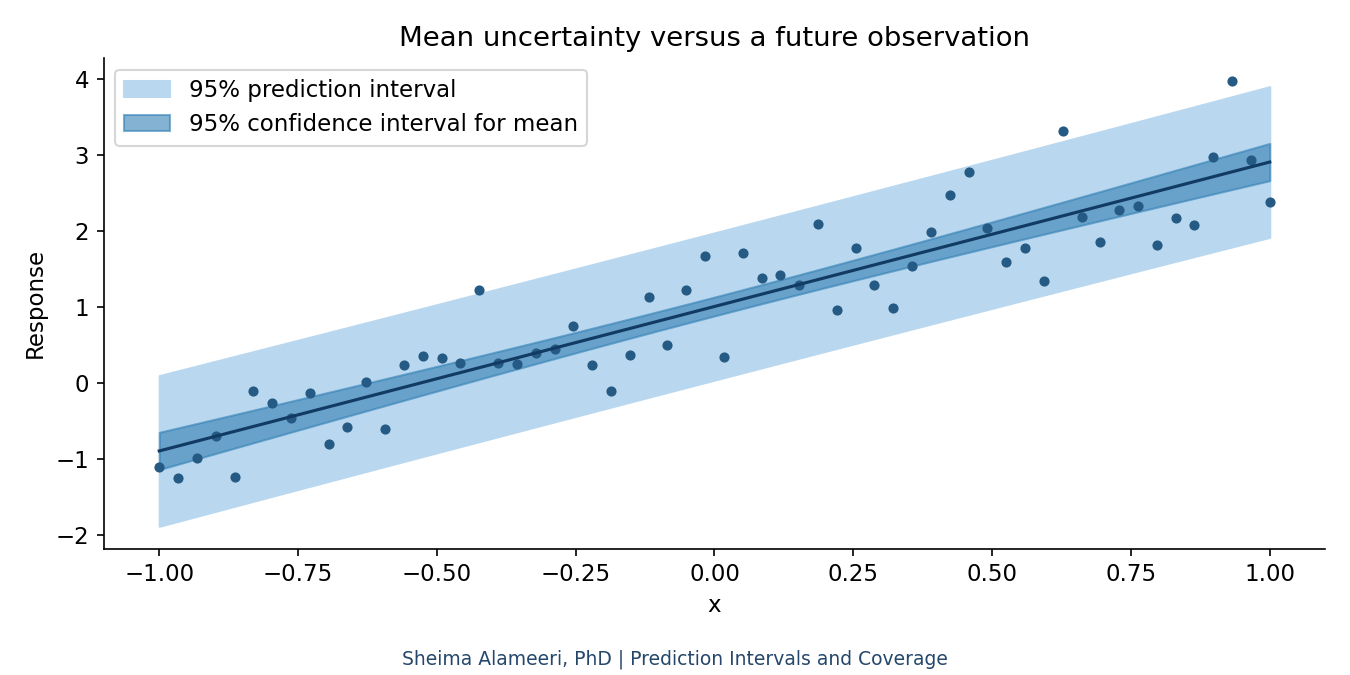

In [2]:
from IPython.display import Image, display
display(Image('assets/intervals.png'))

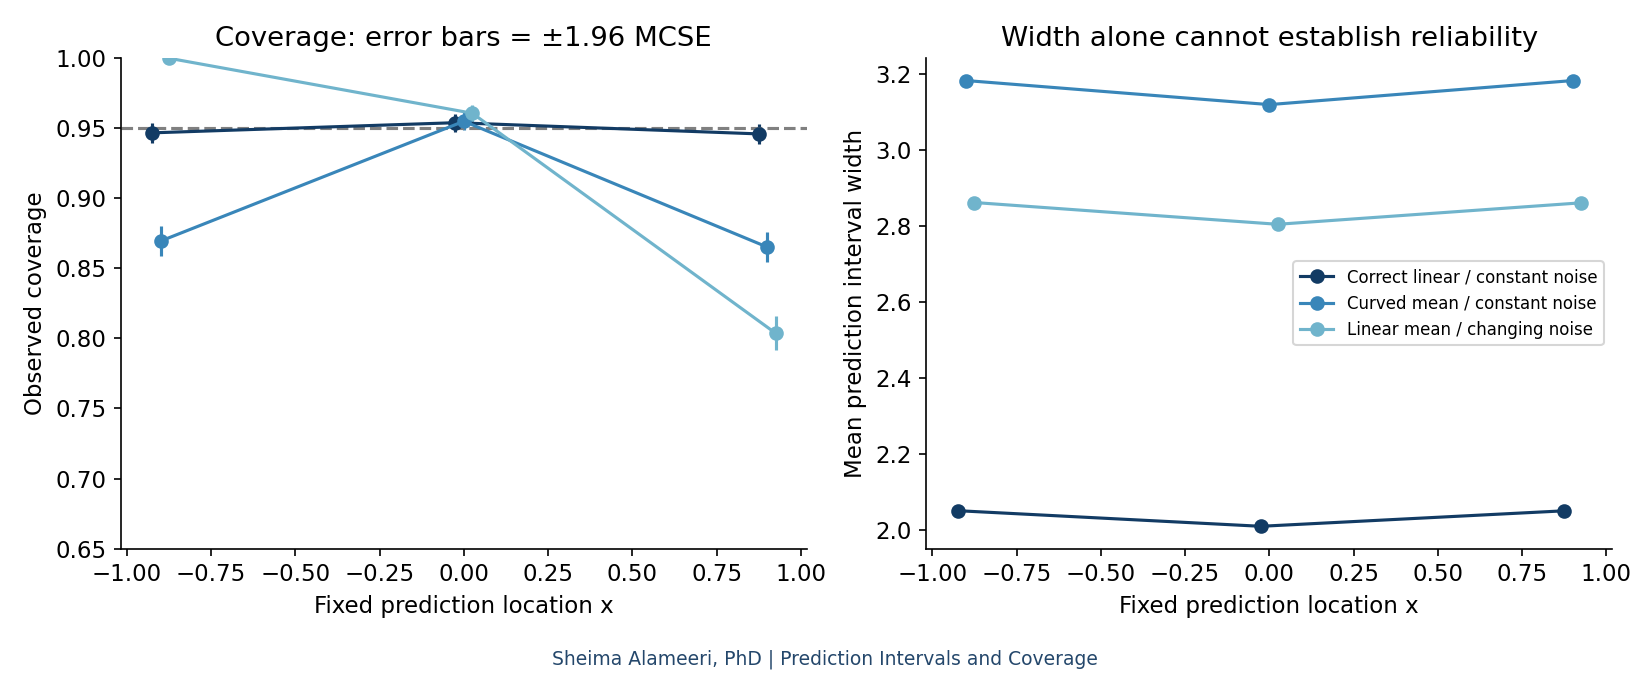

In [3]:
from IPython.display import Image, display
display(Image('assets/coverage-and-width.png'))


## Interpretation and limits
Compare coverage with 0.95 AND examine interval width. Wider is not automatically better; a narrow interval may miss frequently. The curved-mean scenario violates the fitted mean model; changing noise violates constant variance and can overcover low-noise locations while undercovering high-noise locations. This experiment stays within the training input range and does not establish extrapolation reliability. A seed makes results reproducible, not universally guaranteed.

Try changing sample size, noise, curvature, or seed. Repeat the experiment rather than drawing conclusions from one fitted dataset.

## References
- NIST/SEMATECH e-Handbook of Statistical Methods, least-squares estimation: https://www.itl.nist.gov/div898/handbook/pmd/section4/pmd431.htm
- SciPy Student t distribution documentation: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html

Code was newly prepared for this educational project with AI assistance; references credit established theory and software, not copied tutorial code.
